# 02 · SQL findings: where does the company lose money?

**Roadmap step 2.** This notebook runs the seven business queries in `sql/`
against the DuckDB database and presents each one as: the business question,
the query result, one chart, and the insight.

**Every number and insight comes from the SQL files.** The questions and insights
are read from each file's header comments at run time, and every chart is drawn
only from that query's own result. Nothing here adds a new finding.

The queries follow one drill-down: **category → sub-category → discount →
region → state → time → customers**.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.build_database import DB_PATH, build_database
from src.run_sql import execute_sql_file, read_header

SQL_DIR = PROJECT_ROOT / "sql"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# The DuckDB file is not in git; build it if it is missing.
if not DB_PATH.exists():
    build_database()

con = duckdb.connect(str(DB_PATH), read_only=True)
SQL_FILES = sorted(SQL_DIR.glob("[0-9][0-9]_*.sql"))
[f.name for f in SQL_FILES]

['01_category_profitability.sql',
 '02_furniture_subcategories.sql',
 '03_discount_impact_by_category.sql',
 '04_high_discounts_by_region_segment.sql',
 '05_central_states.sql',
 '06_yearly_trends.sql',
 '07_customer_pareto.sql']

In [2]:
# Shared chart style (light mode, reference palette from the dataviz guide).
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # categorical slots 1-3
NEGATIVE = "#e34948"                                   # loss pole (blue <-> red)
CATEGORY_COLORS = {"Furniture": BLUE, "Office Supplies": ORANGE, "Technology": AQUA}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "font.size": 10, "text.color": TEXT,
})


def add_titles(fig, title, subtitle):
    # Left-aligned figure title and subtitle above the plot area.
    fig.text(0.015, 0.965, title, fontsize=12, fontweight="bold", color=TEXT, va="top")
    fig.text(0.015, 0.895, subtitle, fontsize=9, color=TEXT_2, va="top")
    fig.tight_layout(rect=(0, 0, 1, 0.86))


def sign_colors(values):
    # Blue for profit, red for loss.
    return [BLUE if v >= 0 else NEGATIVE for v in values]


def label_bars(ax, bars, fmt, horizontal=True, pad=3):
    # Value label just beyond the end of each bar (left of negative bars).
    for bar in bars:
        value = bar.get_width() if horizontal else bar.get_height()
        if np.isnan(value):
            continue
        offset = pad if value >= 0 else -pad
        if horizontal:
            ax.annotate(fmt(value), (value, bar.get_y() + bar.get_height() / 2),
                        xytext=(offset, 0), textcoords="offset points", va="center",
                        ha="left" if value >= 0 else "right", fontsize=9, color=TEXT)
        else:
            ax.annotate(fmt(value), (bar.get_x() + bar.get_width() / 2, value),
                        xytext=(0, offset), textcoords="offset points", ha="center",
                        va="bottom" if value >= 0 else "top", fontsize=8, color=TEXT)


def save(fig, sql_file):
    # Save as reports/figures/02_<number>_<short_name>.png
    path = FIG_DIR / f"02_{sql_file.stem}.png"
    fig.savefig(path, dpi=150)
    plt.show()
    return path.name

In [3]:
def header_markdown(lines):
    # Turn header comment lines into Markdown paragraphs and bullet lists.
    items = []  # [kind, indent, text]
    for raw in lines:
        if not raw.strip():
            continue
        indent = len(raw) - len(raw.lstrip())
        text = raw.strip()
        if text.startswith("- "):
            items.append(["bullet", indent, text[2:]])
        elif items and items[-1][0] == "bullet" and indent > items[-1][1]:
            items[-1][2] += " " + text
        elif (items and items[-1][0] == "para" and not items[-1][2].endswith(":")
              and not text.endswith(":")):
            items[-1][2] += " " + text
        else:
            items.append(["para", indent, text])
    out, previous = [], None
    for kind, _, text in items:
        text = text.replace("$", "\\$")  # stop Jupyter rendering $...$ as math
        if kind == "para" or previous == "para":
            out.append("")
        if kind == "para" and text.endswith(":") and len(text) <= 30:
            text = f"**{text}**"  # short sub-heading, e.g. "Region:"
        out.append(f"- {text}" if kind == "bullet" else text)
        previous = kind
    return "\n".join(out).strip()


def show_query(sql_file):
    # Show the question and the SQL, run the query, display and return its results.
    header = read_header(sql_file)
    number, name = sql_file.stem.split("_", 1)
    parts = [f"## {number} · {name.replace('_', ' ').capitalize()}",
             f"**Business question:** {header_markdown(header['Business question'])}"]
    if "Why we checked" in header:
        parts.append(f"**Why we checked:** {header_markdown(header['Why we checked'])}")
    sql_text = sql_file.read_text(encoding="utf-8")
    parts.append(f"<details><summary>Show SQL (<code>sql/{sql_file.name}</code>)</summary>\n\n"
                 f"```sql\n{sql_text}\n```\n\n</details>")
    display(Markdown("\n\n".join(parts)))

    results = [df for _, df in execute_sql_file(con, sql_file)]
    for df in results:
        display(df.style.hide(axis="index").format(precision=2, thousands=","))
    return results


def show_insight(sql_file):
    # Show the insight and any caveats / hypothesis / next step from the header.
    header = read_header(sql_file)
    parts = []
    for label in ["Insight", "Caveats", "Caveat", "Hypothesis", "Next"]:
        if label in header:
            body = header_markdown(header[label])
            parts.append(f"**{label}:**\n\n{body}" if label == "Insight" else f"**{label}:** {body}")
    display(Markdown("\n\n".join(parts)))


SQL = {f.stem.split("_")[0]: f for f in SQL_FILES}

In [4]:
sql_file = SQL["01"]
(df,) = show_query(sql_file)

## 01 · Category profitability

**Business question:** What are the sales, profit and profit margin of each category?

<details><summary>Show SQL (<code>sql/01_category_profitability.sql</code>)</summary>

```sql
-- Business question: What are the sales, profit and profit margin of each category?
-- Insight: Furniture generates about a third of total sales but only ~6% of total profit
--          (2.5% margin vs. ~17% in Technology and Office Supplies).
--          Next: drill down into Furniture sub-categories to find where the margin is lost.

SELECT
    T.category,
    ROUND(SUM(T.sales), 2)                                    AS total_sales,
    ROUND(SUM(T.profit), 2)                                   AS total_profit,
    ROUND(SUM(T.sales)  / SUM(SUM(T.sales))  OVER () * 100, 2) AS pct_of_sales,
    ROUND(SUM(T.profit) / SUM(SUM(T.profit)) OVER () * 100, 2) AS pct_of_profit,
    ROUND(SUM(T.profit) / SUM(T.sales) * 100, 2)              AS profit_margin_pct
FROM orders_clean AS T
GROUP BY T.category
ORDER BY total_profit DESC;
```

</details>

category,total_sales,total_profit,pct_of_sales,pct_of_profit,profit_margin_pct
Technology,"836,154.03","145,454.95",36.40,50.79,17.40
Office Supplies,"719,047.03","122,490.80",31.30,42.77,17.04
Furniture,"741,718.42","18,463.33",32.29,6.45,2.49


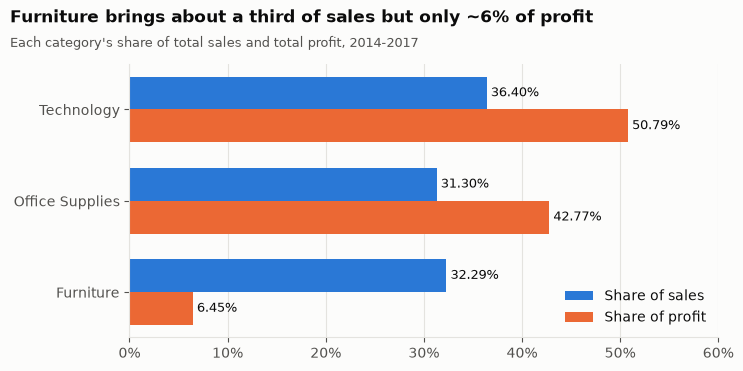

'02_01_category_profitability.png'

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
categories = df["category"][::-1].tolist()
y = np.arange(len(categories))
h = 0.36
b1 = ax.barh(y + h / 2, df["pct_of_sales"][::-1], height=h, color=BLUE, label="Share of sales")
b2 = ax.barh(y - h / 2, df["pct_of_profit"][::-1], height=h, color=ORANGE, label="Share of profit")
label_bars(ax, b1, lambda v: f"{v:.2f}%")
label_bars(ax, b2, lambda v: f"{v:.2f}%")
ax.set_yticks(y, categories)
ax.set_xlim(0, 60)
ax.xaxis.set_major_formatter("{x:.0f}%")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
add_titles(fig, "Furniture brings about a third of sales but only ~6% of profit",
           "Each category's share of total sales and total profit, 2014-2017")
save(fig, sql_file)

In [6]:
show_insight(sql_file)

**Insight:**

Furniture generates about a third of total sales but only ~6% of total profit (2.5% margin vs. ~17% in Technology and Office Supplies).

**Next:** drill down into Furniture sub-categories to find where the margin is lost.

In [7]:
sql_file = SQL["02"]
(df,) = show_query(sql_file)

## 02 · Furniture subcategories

**Business question:** Within Furniture, which sub-categories lose money, and how do their discounts and loss rates compare?

<details><summary>Show SQL (<code>sql/02_furniture_subcategories.sql</code>)</summary>

```sql
-- Business question: Within Furniture, which sub-categories lose money, and how do
--                    their discounts and loss rates compare?
-- Insight: Tables and Bookcases are the only Furniture sub-categories that lose money
--          They also have the highest average discounts (26.13% and 21.11%) and the
--          highest share of loss-making lines.
--          By contrast, Furnishings has the lowest average discount (13.83%) and the
--          highest margin (14.24%).
--          Note: Chairs is profitable (8.11% margin) despite a 17% average discount,
--          so discount is not the only driver.
SELECT
    T.sub_category,                                                   
    ROUND(SUM(T.sales), 2)                                AS total_sales,
    ROUND(SUM(T.profit), 2)                               AS total_profit,
    ROUND(SUM(T.profit) / SUM(T.sales) * 100, 2)          AS profit_margin_pct,
    ROUND(AVG(T.discount) * 100, 2)                       AS avg_discount_pct,   
    ROUND(AVG(CASE WHEN T.is_loss THEN 1 ELSE 0 END) * 100, 2) AS pct_loss_lines 
FROM orders_clean AS T
WHERE T.category = 'Furniture'
GROUP BY T.sub_category
ORDER BY total_profit ASC;                               
```

</details>

sub_category,total_sales,total_profit,profit_margin_pct,avg_discount_pct,pct_loss_lines
Tables,"206,965.53","-17,725.48",-8.56,26.13,63.64
Bookcases,"114,880.00","-3,472.56",-3.02,21.11,47.81
Furnishings,"91,705.16","13,059.14",14.24,13.83,17.45
Chairs,"328,167.73","26,602.23",8.11,17.00,37.99


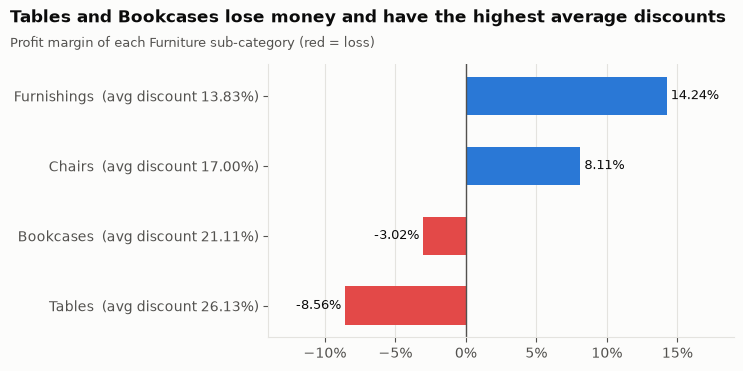

'02_02_furniture_subcategories.png'

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
plot = df.sort_values("profit_margin_pct")
labels = [f"{s}  (avg discount {d:.2f}%)" for s, d in zip(plot["sub_category"], plot["avg_discount_pct"])]
bars = ax.barh(labels, plot["profit_margin_pct"], color=sign_colors(plot["profit_margin_pct"]), height=0.55)
label_bars(ax, bars, lambda v: f"{v:.2f}%")
ax.axvline(0, color=TEXT_2, lw=1)
ax.set_xlim(-14, 19)
ax.xaxis.set_major_formatter("{x:.0f}%")
ax.grid(axis="y", visible=False)
add_titles(fig, "Tables and Bookcases lose money and have the highest average discounts",
           "Profit margin of each Furniture sub-category (red = loss)")
save(fig, sql_file)

In [9]:
show_insight(sql_file)

**Insight:**

Tables and Bookcases are the only Furniture sub-categories that lose money They also have the highest average discounts (26.13% and 21.11%) and the highest share of loss-making lines. By contrast, Furnishings has the lowest average discount (13.83%) and the highest margin (14.24%). Note: Chairs is profitable (8.11% margin) despite a 17% average discount, so discount is not the only driver.

In [10]:
sql_file = SQL["03"]
(df,) = show_query(sql_file)

## 03 · Discount impact by category

**Business question:** Do high discounts lead to losses in every category, or only in Furniture?

**Why we checked:** In query 02, the two loss-making Furniture sub-categories (Tables, Bookcases) also had the highest average discounts. That raised a suspicion that discounts drive losses. But it could have been a Furniture-only problem, so we tested the same pattern in all categories.

<details><summary>Show SQL (<code>sql/03_discount_impact_by_category.sql</code>)</summary>

```sql
-- Business question: Do high discounts lead to losses in every category,
--                    or only in Furniture?
-- Why we checked: In query 02, the two loss-making Furniture sub-categories (Tables,
--                 Bookcases) also had the highest average discounts. That raised a
--                 suspicion that discounts drive losses. But it could have been a
--                 Furniture-only problem, so we tested the same pattern in all categories.
-- Insight: The pattern holds in every category, so this is a company-wide discount issue.
--          - With no discount, 0% of order lines lose money in all three categories
--            (margins of 22.7%-34.0%).
--          - At 1-20%, lines stay profitable overall, but margins drop sharply
--            (e.g. Technology 34.0% -> 14.7%).
--          - Above 20%, every category loses money: 78%-100% of lines are loss-making,
--            and Office Supplies at >40% loses more than its revenue (-119% margin).
--          - Lines with discounts above 20% lose a combined $135,364, equal to about 47%
--            of the company's total profit ($286,409).
--          - Furniture is also weak at 1-20% (5.1% margin vs. 14.7%-16.5% elsewhere),
--            so discounts explain part, but not all, of its low profitability.
-- Caveats: Technology >40% is based on only 35 lines. This shows a strong association,
--          not proof that discounts cause the losses.
-- Next: test the discount effect while controlling for product and price (ML step),
--       and look at which regions and customer segments receive the high discounts.
SELECT
    T.category,
    T.discount_band,
    COUNT(*)                                                   AS order_lines,
    ROUND(SUM(T.sales), 2)                                     AS total_sales,
    ROUND(SUM(T.profit), 2)                                    AS total_profit,
    ROUND(SUM(T.profit) / SUM(T.sales) * 100, 2)               AS profit_margin_pct,
    ROUND(AVG(CASE WHEN T.is_loss THEN 1 ELSE 0 END) * 100, 2) AS pct_loss_lines
FROM orders_clean AS T
GROUP BY T.category, T.discount_band
ORDER BY T.category, MIN(T.discount);
```

</details>

category,discount_band,order_lines,total_sales,total_profit,profit_margin_pct,pct_loss_lines
Furniture,0%,836,"256,025.27","58,133.08",22.71,0.00
Furniture,1-20%,743,"290,823.78","14,795.95",5.09,25.17
Furniture,21-40%,323,"159,296.84","-29,261.79",-18.37,95.36
Furniture,>40%,218,"35,572.53","-25,203.90",-70.85,100.00
Office Supplies,0%,"3,129","442,150.00","130,506.11",29.52,0.00
Office Supplies,1-20%,"2,217","237,373.89","39,124.83",16.48,9.29
Office Supplies,>40%,680,"39,523.15","-47,140.14",-119.27,100.00
Technology,0%,833,"389,733.20","132,348.42",33.96,0.00
Technology,1-20%,843,"318,324.57","46,864.69",14.72,15.42
Technology,21-40%,136,"74,559.68","-6,543.61",-8.78,77.94


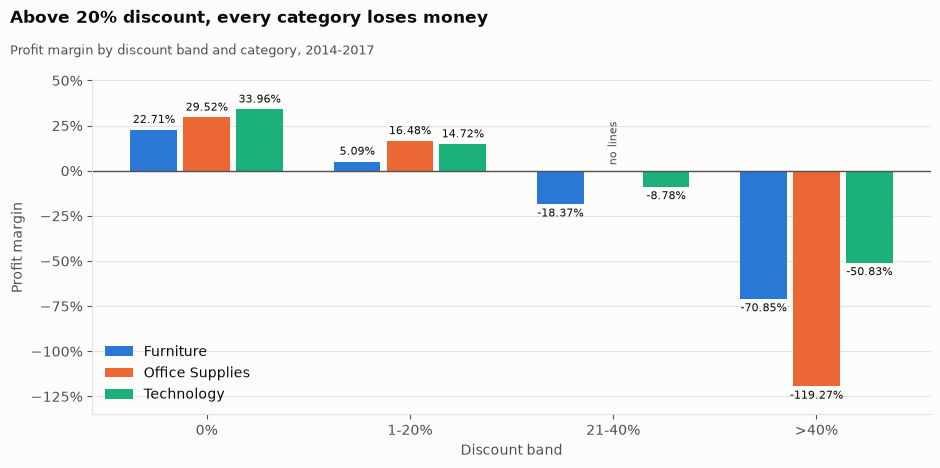

'02_03_discount_impact_by_category.png'

In [11]:
bands = ["0%", "1-20%", "21-40%", ">40%"]
pivot = df.pivot(index="discount_band", columns="category", values="profit_margin_pct").reindex(bands)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
x = np.arange(len(bands))
w = 0.26
for i, category in enumerate(pivot.columns):
    bars = ax.bar(x + (i - 1) * w, pivot[category], width=w - 0.03,
                  color=CATEGORY_COLORS[category], label=category)
    label_bars(ax, bars, lambda v: f"{v:.2f}%", horizontal=False)
for i, category in enumerate(pivot.columns):
    for j, band in enumerate(bands):
        if np.isnan(pivot.loc[band, category]):
            ax.annotate("no lines", (x[j] + (i - 1) * w, 0), xytext=(0, 4),
                        textcoords="offset points", ha="center", fontsize=8,
                        color=TEXT_2, rotation=90, va="bottom")
ax.axhline(0, color=TEXT_2, lw=1)
ax.set_xticks(x, bands)
ax.set_xlabel("Discount band")
ax.set_ylabel("Profit margin")
ax.set_ylim(-135, 50)
ax.yaxis.set_major_formatter("{x:.0f}%")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower left", frameon=False)
add_titles(fig, "Above 20% discount, every category loses money",
           "Profit margin by discount band and category, 2014-2017")
save(fig, sql_file)

In [12]:
show_insight(sql_file)

**Insight:**

The pattern holds in every category, so this is a company-wide discount issue.

- With no discount, 0% of order lines lose money in all three categories (margins of 22.7%-34.0%).
- At 1-20%, lines stay profitable overall, but margins drop sharply (e.g. Technology 34.0% -> 14.7%).
- Above 20%, every category loses money: 78%-100% of lines are loss-making, and Office Supplies at >40% loses more than its revenue (-119% margin).
- Lines with discounts above 20% lose a combined \$135,364, equal to about 47% of the company's total profit (\$286,409).
- Furniture is also weak at 1-20% (5.1% margin vs. 14.7%-16.5% elsewhere), so discounts explain part, but not all, of its low profitability.

**Caveats:** Technology >40% is based on only 35 lines. This shows a strong association, not proof that discounts cause the losses.

**Next:** test the discount effect while controlling for product and price (ML step), and look at which regions and customer segments receive the high discounts.

In [13]:
sql_file = SQL["04"]
by_region, by_segment = show_query(sql_file)

## 04 · High discounts by region segment

**Business question:** Which regions and customer segments receive high discounts (above 20%), and how much profit do those discounts cost?

**Why we checked:** Query 03 showed that lines with discounts above 20% lose money in every category. The next question is where those discounts are given.

<details><summary>Show SQL (<code>sql/04_high_discounts_by_region_segment.sql</code>)</summary>

```sql
-- Business question: Which regions and customer segments receive high discounts
--                    (above 20%), and how much profit do those discounts cost?
-- Why we checked: Query 03 showed that lines with discounts above 20% lose money in
--                 every category. The next question is where those discounts are given.
-- Insight: High discounts are concentrated by region, not by customer segment.
--          Region:
--          - Central gives by far the most high discounts: 27.68% of its lines are
--            discounted above 20%, vs. only 3.68% in West (about 7.5x more).
--          - Central also has the lowest margin (7.92%), and its high-discount lines
--            lose $52,392, more than its entire total profit ($39,706).
--          - West has the lowest discounts and the highest margin (14.94%).
--          - The link is not perfect: South has fewer high-discount lines than East
--            (10.56% vs. 16.16%) but a lower margin (11.93% vs. 13.49%).
--          Segment:
--          - The three segments get almost identical discounts (13.30%-14.16% of lines
--            above 20%), so customer type does not explain the losses.
--          - Consumer has the largest loss in dollars (-$71,890) only because it has
--            the most order lines, not because it is treated differently.
--          Check: high-discount losses add up to -$135,364 in both tables, matching query 03.
-- Next: drill into Central to find which states give the high discounts.
SELECT
    T.region,
    COUNT(*)                                                         AS order_lines,
    ROUND(AVG(T.discount) * 100, 2)                                  AS avg_discount_pct,
    ROUND(AVG(CASE WHEN T.discount > 0.2 THEN 1 ELSE 0 END) * 100, 2) AS pct_high_discount_lines,
    ROUND(SUM(T.profit), 2)                                          AS total_profit,
    ROUND(SUM(T.profit) / SUM(T.sales) * 100, 2)                     AS profit_margin_pct,
    ROUND(SUM(CASE WHEN T.discount > 0.2 THEN T.profit ELSE 0 END), 2) AS profit_from_high_discounts
FROM orders_clean AS T
GROUP BY T.region
ORDER BY profit_margin_pct ASC;

-- Part 2: by customer segment
SELECT
    T.segment,
    COUNT(*)                                                         AS order_lines,
    ROUND(AVG(T.discount) * 100, 2)                                  AS avg_discount_pct,
    ROUND(AVG(CASE WHEN T.discount > 0.2 THEN 1 ELSE 0 END) * 100, 2) AS pct_high_discount_lines,
    ROUND(SUM(T.profit), 2)                                          AS total_profit,
    ROUND(SUM(T.profit) / SUM(T.sales) * 100, 2)                     AS profit_margin_pct,
    ROUND(SUM(CASE WHEN T.discount > 0.2 THEN T.profit ELSE 0 END), 2) AS profit_from_high_discounts
FROM orders_clean AS T
GROUP BY T.segment
ORDER BY profit_margin_pct ASC;
```

</details>

region,order_lines,avg_discount_pct,pct_high_discount_lines,total_profit,profit_margin_pct,profit_from_high_discounts
Central,"2,323",24.04,27.68,"39,706.36",7.92,"-52,392.27"
South,"1,620",14.73,10.56,"46,749.43",11.93,"-24,880.48"
East,"2,847",14.53,16.16,"91,534.84",13.49,"-42,076.55"
West,"3,203",10.93,3.68,"108,418.45",14.94,"-16,014.69"


segment,order_lines,avg_discount_pct,pct_high_discount_lines,total_profit,profit_margin_pct,profit_from_high_discounts
Consumer,"5,191",15.81,14.16,"134,119.21",11.55,"-71,890.16"
Corporate,"3,020",15.82,13.91,"91,979.13",13.03,"-39,770.76"
Home Office,"1,782",14.70,13.30,"60,310.74",14.05,"-23,703.07"


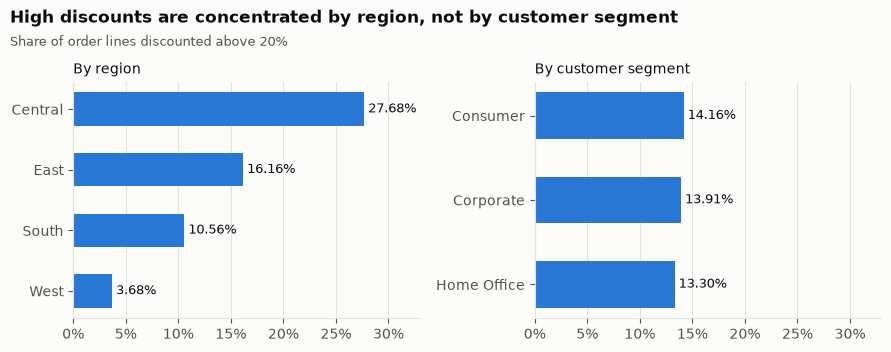

'02_04_high_discounts_by_region_segment.png'

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True)
for ax, frame, key, heading in [(ax1, by_region, "region", "By region"),
                                (ax2, by_segment, "segment", "By customer segment")]:
    plot = frame.sort_values("pct_high_discount_lines")
    bars = ax.barh(plot[key], plot["pct_high_discount_lines"], color=BLUE, height=0.55)
    label_bars(ax, bars, lambda v: f"{v:.2f}%")
    ax.set_title(heading, loc="left", fontsize=10, color=TEXT)
    ax.grid(axis="y", visible=False)
ax1.set_xlim(0, 33)
ax1.xaxis.set_major_formatter("{x:.0f}%")
add_titles(fig, "High discounts are concentrated by region, not by customer segment",
           "Share of order lines discounted above 20%")
save(fig, sql_file)

In [15]:
show_insight(sql_file)

**Insight:**

High discounts are concentrated by region, not by customer segment.

**Region:**

- Central gives by far the most high discounts: 27.68% of its lines are discounted above 20%, vs. only 3.68% in West (about 7.5x more).
- Central also has the lowest margin (7.92%), and its high-discount lines lose \$52,392, more than its entire total profit (\$39,706).
- West has the lowest discounts and the highest margin (14.94%).
- The link is not perfect: South has fewer high-discount lines than East (10.56% vs. 16.16%) but a lower margin (11.93% vs. 13.49%).

**Segment:**

- The three segments get almost identical discounts (13.30%-14.16% of lines above 20%), so customer type does not explain the losses.
- Consumer has the largest loss in dollars (-\$71,890) only because it has the most order lines, not because it is treated differently.

Check: high-discount losses add up to -\$135,364 in both tables, matching query 03.

**Next:** drill into Central to find which states give the high discounts.

In [16]:
sql_file = SQL["05"]
(df,) = show_query(sql_file)

## 05 · Central states

**Business question:** Within the Central region, which states give the high discounts and account for the losses?

**Why we checked:** Query 04 showed that Central gives the most high discounts (27.68% of lines above 20%) and has the lowest margin (7.92%).

<details><summary>Show SQL (<code>sql/05_central_states.sql</code>)</summary>

```sql
-- Business question: Within the Central region, which states give the high discounts
--                    and account for the losses?
-- Why we checked: Query 04 showed that Central gives the most high discounts
--                 (27.68% of lines above 20%) and has the lowest margin (7.92%).
-- Insight: Central's discount problem comes from just two states: Texas and Illinois.
--          - They are the only Central states that give discounts at all (average
--            37.02% and 39.00%); the other 11 states give almost none (0%-0.71%).
--          - Both lose money (-$25,729 and -$12,608; margins of about -15%), while
--            every other Central state is profitable with margins of 24.66%-36.24%.
--          - Their high-discount lines lose $33,955 + $18,437 = $52,392, which is all of
--            Central's high-discount loss from query 04.
--          - Texas is also Central's largest state by sales ($170,188), so the problem
--            sits in one of the region's most important markets.
--          This suggests discounts are set by state-level policy, not by product or
--          customer. Caveat: several states have very few order lines (e.g. North Dakota: 7).
-- Next: check whether the same pattern appears in other regions, and follow how
--       sales and profit changed over time.
SELECT
    T.state,
    COUNT(*)                                                           AS order_lines,
    ROUND(AVG(T.discount) * 100, 2)                                    AS avg_discount_pct,
    ROUND(AVG(CASE WHEN T.discount > 0.2 THEN 1 ELSE 0 END) * 100, 2)   AS pct_high_discount_lines,
    ROUND(SUM(T.sales), 2)                                             AS total_sales,
    ROUND(SUM(T.profit), 2)                                            AS total_profit,
    ROUND(SUM(T.profit) / SUM(T.sales) * 100, 2)                       AS profit_margin_pct,
    ROUND(SUM(CASE WHEN T.discount > 0.2 THEN T.profit ELSE 0 END), 2) AS profit_from_high_discounts
FROM orders_clean AS T
WHERE T.region = 'Central'
GROUP BY T.state
ORDER BY total_profit ASC;
```

</details>

state,order_lines,avg_discount_pct,pct_high_discount_lines,total_sales,total_profit,profit_margin_pct,profit_from_high_discounts
Texas,985,37.02,42.13,"170,188.05","-25,729.36",-15.12,"-33,955.28"
Illinois,492,39.00,46.34,"80,166.10","-12,607.89",-15.73,"-18,436.99"
North Dakota,7,0.00,0.00,919.91,230.15,25.02,0.00
South Dakota,12,0.00,0.00,"1,315.56",394.83,30.01,0.00
Kansas,24,0.00,0.00,"2,914.31",836.44,28.70,0.00
Iowa,30,0.00,0.00,"4,579.76","1,183.81",25.85,0.00
Nebraska,38,0.00,0.00,"7,464.93","2,037.09",27.29,0.00
Oklahoma,66,0.00,0.00,"19,683.39","4,853.96",24.66,0.00
Missouri,66,0.00,0.00,"22,205.15","6,436.21",28.99,0.00
Wisconsin,110,0.00,0.00,"32,114.61","8,401.80",26.16,0.00


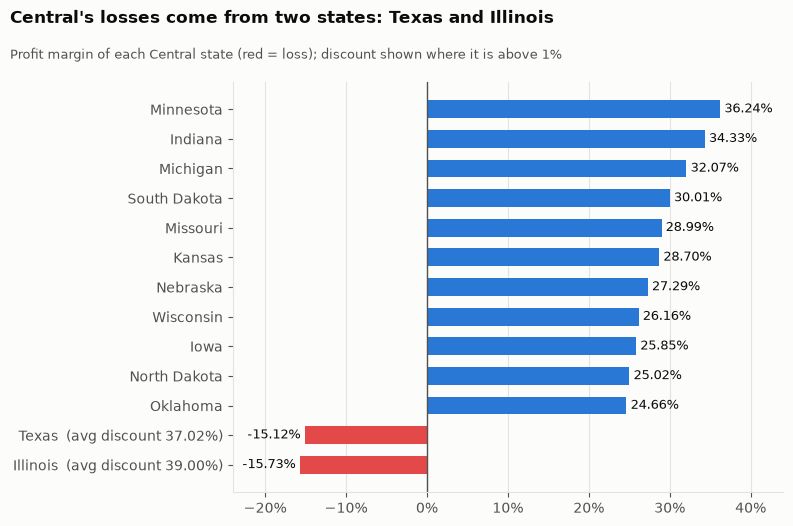

'02_05_central_states.png'

In [17]:
fig, ax = plt.subplots(figsize=(8, 5.4))
plot = df.sort_values("profit_margin_pct")
labels = [f"{s}  (avg discount {d:.2f}%)" if d > 1 else s
          for s, d in zip(plot["state"], plot["avg_discount_pct"])]
bars = ax.barh(labels, plot["profit_margin_pct"], color=sign_colors(plot["profit_margin_pct"]), height=0.6)
label_bars(ax, bars, lambda v: f"{v:.2f}%")
ax.axvline(0, color=TEXT_2, lw=1)
ax.set_xlim(-24, 44)
ax.xaxis.set_major_formatter("{x:.0f}%")
ax.grid(axis="y", visible=False)
add_titles(fig, "Central's losses come from two states: Texas and Illinois",
           "Profit margin of each Central state (red = loss); discount shown where it is above 1%")
save(fig, sql_file)

In [18]:
show_insight(sql_file)

**Insight:**

Central's discount problem comes from just two states: Texas and Illinois.

- They are the only Central states that give discounts at all (average 37.02% and 39.00%); the other 11 states give almost none (0%-0.71%).
- Both lose money (-\$25,729 and -\$12,608; margins of about -15%), while every other Central state is profitable with margins of 24.66%-36.24%.
- Their high-discount lines lose \$33,955 + \$18,437 = \$52,392, which is all of Central's high-discount loss from query 04.
- Texas is also Central's largest state by sales (\$170,188), so the problem sits in one of the region's most important markets.

This suggests discounts are set by state-level policy, not by product or customer. Caveat: several states have very few order lines (e.g. North Dakota: 7).

**Next:** check whether the same pattern appears in other regions, and follow how sales and profit changed over time.

In [19]:
sql_file = SQL["06"]
yearly, _text_chart = show_query(sql_file)

## 06 · Yearly trends

**Business question:** How did sales, profit and discounting change from year to year?

**Why we checked:** Queries 01-05 looked at all four years together. We need to know whether the business is growing and whether the discount problem is getting better or worse over time.

<details><summary>Show SQL (<code>sql/06_yearly_trends.sql</code>)</summary>

```sql
-- Business question: How did sales, profit and discounting change from year to year?
-- Why we checked: Queries 01-05 looked at all four years together. We need to know
--                 whether the business is growing and whether the discount problem
--                 is getting better or worse over time.
--  Insight: The business is growing, but growth became less profitable in 2017.
--          - Sales grew from $483,966 (2014) to $733,215 (2017), about +51.5%,
--            and orders grew from 969 to 1,687.
--          - Through 2016, profit grew faster than sales (2016: sales +29.47%,
--            profit +32.74%). In 2017 this reversed: sales +20.36% but profit only
--            +14.24%, and the margin fell from 13.43% to 12.74%. This is one year,
--            so it is an early warning sign rather than a proven trend.
--          - The share of high-discount lines stayed almost the same every year
--            (13.74%-14.11%), so the discount pattern is a stable, long-running policy,
--            not a new one. Addressing it could improve profit in every future year.
-- Next: measure how much of the profit comes from the top customers (Pareto analysis).

SELECT
    T.order_year,
    COUNT(DISTINCT T.order_id)                                        AS orders,
    COUNT(DISTINCT T.customer_id)                                     AS active_customers,
    ROUND(SUM(T.sales), 2)                                            AS total_sales,
    ROUND(SUM(T.profit), 2)                                           AS total_profit,
    ROUND(SUM(T.profit) / SUM(T.sales) * 100, 2)                      AS profit_margin_pct,
    ROUND(
        (SUM(T.sales) - LAG(SUM(T.sales)) OVER (ORDER BY T.order_year))
        / LAG(SUM(T.sales)) OVER (ORDER BY T.order_year) * 100, 2)    AS sales_growth_pct,
    ROUND(
        (SUM(T.profit) - LAG(SUM(T.profit)) OVER (ORDER BY T.order_year))
        / LAG(SUM(T.profit)) OVER (ORDER BY T.order_year) * 100, 2)   AS profit_growth_pct,
    ROUND(AVG(CASE WHEN T.discount > 0.2 THEN 1 ELSE 0 END) * 100, 2) AS pct_high_discount_lines
FROM orders_clean AS T
GROUP BY T.order_year
ORDER BY T.order_year;


-- Part 2: text chart of sales and profit over time (DuckDB bar() function).
-- Each bar has its own scale: sales up to $800K, profit up to $100K.
SELECT
    T.order_year,
    ROUND(SUM(T.sales), 0)               AS total_sales,
    bar(SUM(T.sales), 0, 800000, 30)     AS sales_chart,
    ROUND(SUM(T.profit), 0)              AS total_profit,
    bar(SUM(T.profit), 0, 100000, 30)    AS profit_chart
FROM orders_clean AS T
GROUP BY T.order_year
ORDER BY T.order_year;
```

</details>

order_year,orders,active_customers,total_sales,total_profit,profit_margin_pct,sales_growth_pct,profit_growth_pct,pct_high_discount_lines
"2,014",969,595,"483,966.13","49,556.03",10.24,nan,nan,14.11
"2,015","1,038",573,"470,532.51","61,618.60",13.10,-2.78,24.34,13.94
"2,016","1,315",638,"609,205.60","81,795.17",13.43,29.47,32.74,14.03
"2,017","1,687",693,"733,215.26","93,439.27",12.74,20.36,14.24,13.74


order_year,total_sales,sales_chart,total_profit,profit_chart
"2,014","483,966.00",██████████████████▏,"49,556.00",██████████████▊
"2,015","470,533.00",█████████████████▋,"61,619.00",██████████████████▍
"2,016","609,206.00",██████████████████████▊,"81,795.00",████████████████████████▌
"2,017","733,215.00",███████████████████████████▍,"93,439.00",████████████████████████████


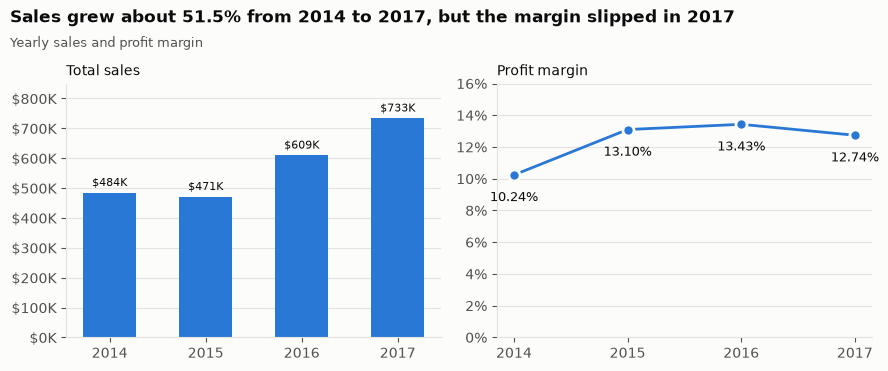

'02_06_yearly_trends.png'

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))
years = yearly["order_year"].astype(str)
bars = ax1.bar(years, yearly["total_sales"] / 1000, color=BLUE, width=0.55)
label_bars(ax1, bars, lambda v: f"${v:,.0f}K", horizontal=False)
ax1.set_title("Total sales", loc="left", fontsize=10, color=TEXT)
ax1.set_ylim(0, 850)
ax1.yaxis.set_major_formatter("${x:,.0f}K")
ax1.grid(axis="x", visible=False)

ax2.plot(years, yearly["profit_margin_pct"], color=BLUE, lw=2, marker="o", ms=8,
         markeredgecolor=SURFACE, markeredgewidth=2)
for xi, v in zip(years, yearly["profit_margin_pct"]):
    ax2.annotate(f"{v:.2f}%", (xi, v), xytext=(0, -12), textcoords="offset points",
                 ha="center", va="top", fontsize=9, color=TEXT)
ax2.set_title("Profit margin", loc="left", fontsize=10, color=TEXT)
ax2.set_ylim(0, 16)
ax2.yaxis.set_major_formatter("{x:.0f}%")
ax2.grid(axis="x", visible=False)
add_titles(fig, "Sales grew about 51.5% from 2014 to 2017, but the margin slipped in 2017",
           "Yearly sales and profit margin")
save(fig, sql_file)

In [21]:
show_insight(sql_file)

**Insight:**

The business is growing, but growth became less profitable in 2017.

- Sales grew from \$483,966 (2014) to \$733,215 (2017), about +51.5%, and orders grew from 969 to 1,687.
- Through 2016, profit grew faster than sales (2016: sales +29.47%, profit +32.74%). In 2017 this reversed: sales +20.36% but profit only +14.24%, and the margin fell from 13.43% to 12.74%. This is one year, so it is an early warning sign rather than a proven trend.
- The share of high-discount lines stayed almost the same every year (13.74%-14.11%), so the discount pattern is a stable, long-running policy, not a new one. Addressing it could improve profit in every future year.

**Next:** measure how much of the profit comes from the top customers (Pareto analysis).

In [22]:
sql_file = SQL["07"]
(df,) = show_query(sql_file)

## 07 · Customer pareto

**Business question:** How much of the total profit comes from the top customers, and are some customers unprofitable?

**Why we checked:** Queries 01-06 looked at products, discounts, regions and time. The last view is the customer: is profit concentrated in a few customers?

<details><summary>Show SQL (<code>sql/07_customer_pareto.sql</code>)</summary>

```sql
-- Business question: How much of the total profit comes from the top customers,
--                    and are some customers unprofitable?
-- Why we checked: Queries 01-06 looked at products, discounts, regions and time.
--                 The last view is the customer: is profit concentrated in a few customers?
-- Insight: Profit is highly concentrated, and about 1 in 5 customers loses money.
--          - The top 10% of customers (80) generate 57.69% of total profit, and the
--            top 20% generate 81.90%, a classic Pareto (80/20) pattern.
--          - 155 of 793 customers (deciles 9-10) are unprofitable. Profitable customers
--            earn 124.86% of total profit, and the unprofitable ones erase about a
--            quarter of it (cumulative share falls from 124.86% back to 100%).
--          - The bottom decile is not small: it bought $278,279, the third-largest
--            sales of any decile, yet lost $65,754. These are big buyers that lose money.
-- Hypothesis: the unprofitable customers buy mostly at high discounts (links to 03-05).
-- Next: test this in the customer segmentation step (RFM) and the ML model.

WITH customer_profit AS (
    -- Step 1: one row per customer with their total sales and profit
    SELECT
        T.customer_id,
        SUM(T.sales)  AS sales,
        SUM(T.profit) AS profit
    FROM orders_clean AS T
    GROUP BY T.customer_id
),
customer_deciles AS (
    -- Step 2: split customers into 10 equal groups, from most to least profitable
    SELECT
        *,
        NTILE(10) OVER (ORDER BY profit DESC) AS decile
    FROM customer_profit
)
-- Step 3: summarize each decile
SELECT
    decile,
    COUNT(*)                                                         AS customers,
    ROUND(SUM(sales), 2)                                             AS total_sales,
    ROUND(SUM(profit), 2)                                            AS total_profit,
    ROUND(SUM(profit) / SUM(SUM(profit)) OVER () * 100, 2)           AS pct_of_profit,
    ROUND(SUM(SUM(profit)) OVER (ORDER BY decile)
          / SUM(SUM(profit)) OVER () * 100, 2)                       AS cumulative_pct_of_profit,
    SUM(CASE WHEN profit < 0 THEN 1 ELSE 0 END)                      AS unprofitable_customers
FROM customer_deciles
GROUP BY decile
ORDER BY decile;
```

</details>

decile,customers,total_sales,total_profit,pct_of_profit,cumulative_pct_of_profit,unprofitable_customers
1,80,"603,295.26","165,235.41",57.69,57.69,0
2,80,"344,693.39","69,333.06",24.21,81.90,0
3,80,"255,883.94","44,541.35",15.55,97.45,0
4,79,"190,688.09","30,022.18",10.48,107.93,0
5,79,"166,691.78","21,061.81",7.35,115.29,0
6,79,"148,553.18","15,168.77",5.30,120.58,0
7,79,"105,272.21","9,118.32",3.18,123.77,0
8,79,"89,338.44","3,139.71",1.10,124.86,0
9,79,"114,224.15","-5,457.89",-1.91,122.96,76
10,79,"278,279.04","-65,753.64",-22.96,100.00,79


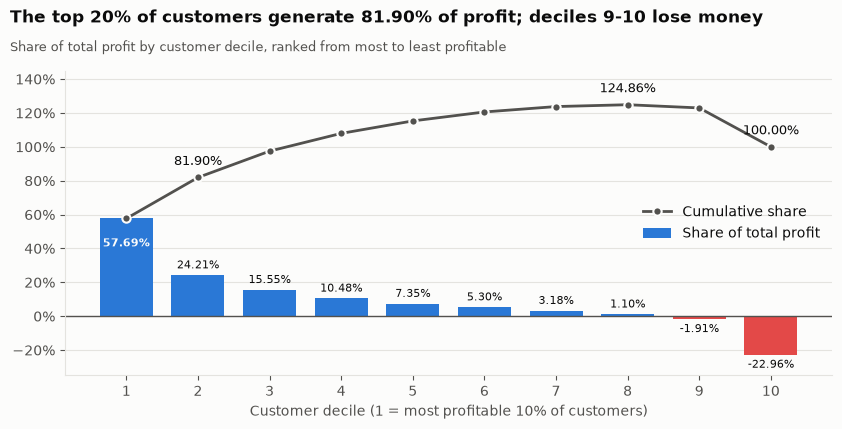

'02_07_customer_pareto.png'

In [23]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
deciles = df["decile"].astype(str)
bars = ax.bar(deciles, df["pct_of_profit"], color=sign_colors(df["pct_of_profit"]),
              width=0.74, label="Share of total profit")
label_bars(ax, bars[1:], lambda v: f"{v:.2f}%", horizontal=False)
first = bars[0]
ax.annotate(f"{first.get_height():.2f}%", (first.get_x() + first.get_width() / 2, first.get_height()),
            xytext=(0, -14), textcoords="offset points", ha="center", va="top",
            fontsize=8, color=SURFACE, fontweight="bold")
ax.plot(deciles, df["cumulative_pct_of_profit"], color=TEXT_2, lw=2, marker="o", ms=6,
        markeredgecolor=SURFACE, markeredgewidth=1.5, label="Cumulative share")
for i in [1, 7, 9]:  # top 20%, peak, final 100%
    v = df["cumulative_pct_of_profit"].iloc[i]
    ax.annotate(f"{v:.2f}%", (deciles.iloc[i], v), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=TEXT)
ax.axhline(0, color=TEXT_2, lw=1)
ax.set_xlabel("Customer decile (1 = most profitable 10% of customers)")
ax.set_ylim(-35, 145)
ax.yaxis.set_major_formatter("{x:.0f}%")
ax.grid(axis="x", visible=False)
ax.legend(loc="center right", frameon=False)
add_titles(fig, "The top 20% of customers generate 81.90% of profit; deciles 9-10 lose money",
           "Share of total profit by customer decile, ranked from most to least profitable")
save(fig, sql_file)

In [24]:
show_insight(sql_file)

**Insight:**

Profit is highly concentrated, and about 1 in 5 customers loses money.

- The top 10% of customers (80) generate 57.69% of total profit, and the top 20% generate 81.90%, a classic Pareto (80/20) pattern.
- 155 of 793 customers (deciles 9-10) are unprofitable. Profitable customers earn 124.86% of total profit, and the unprofitable ones erase about a quarter of it (cumulative share falls from 124.86% back to 100%).
- The bottom decile is not small: it bought \$278,279, the third-largest sales of any decile, yet lost \$65,754. These are big buyers that lose money.

**Hypothesis:** the unprofitable customers buy mostly at high discounts (links to 03-05).

**Next:** test this in the customer segmentation step (RFM) and the ML model.

## Summary: the drill-down story

Each step below restates the insight already written in that query's header.

1. **Category (01).** Furniture brings about a third of sales but only ~6% of profit
   (2.5% margin vs. ~17% for Technology and Office Supplies).
2. **Sub-category (02).** Within Furniture, Tables and Bookcases are the only
   sub-categories that lose money, and they carry the highest average discounts
   (26.13% and 21.11%).
3. **Discount (03).** The discount pattern holds in every category: with no discount
   no lines lose money, but above 20% every category loses money. Those lines lose
   a combined \$135,364, about 47% of total profit (\$286,409).
4. **Region (04).** High discounts are concentrated by region, not by customer
   segment: 27.68% of Central's lines are discounted above 20% vs. 3.68% in West,
   and Central's high-discount lines lose more than its entire profit.
5. **State (05).** Inside Central, the problem is just two states, Texas and Illinois.
   They are the only Central states that discount (37.02% and 39.00% on average),
   both lose money, and their high-discount lines account for all \$52,392 of
   Central's high-discount loss.
6. **Time (06).** The business is growing (sales about +51.5% from 2014 to 2017), but
   the 2017 margin fell from 13.43% to 12.74%. The share of high-discount lines stayed
   at 13.74%-14.11% every year, so the discount pattern is a stable policy.
7. **Customers (07).** Profit is concentrated: the top 20% of customers generate
   81.90% of profit, while 155 of 793 customers lose money. The bottom decile bought
   \$278,279 yet lost \$65,754.

**Answer to the core question so far:** the company loses money mainly on order
lines discounted above 20%. That discounting is concentrated in specific places
(Central's Texas and Illinois) rather than in customer segments, and it has been
stable for four years. The headers point to the next steps: test the discount effect
while controlling for product and price (ML), and test whether unprofitable
customers buy mostly at high discounts (RFM).

In [25]:
con.close()